In [1]:
import inspect
import os
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm

from Regression_utils import *
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


In [2]:
main_df = pd.read_excel(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'Workover Info', 'Workover Cost', 'Pump Model',
       'Pump Number', 'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'KWH per Barrel', 'Cost per KWH',
       'Electrical Cost per Barrel', 'Maintenance Cost per Barrel',
       'Workover Cost per Barrel', 'Revenue per Barrel', 'Income per Barrel',
       'Income', 'Total Cost', '6 Month Avg Water Total', '6 Month Avg KWH',
       '6 Month Avg Revenue', '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Electrical Cost', 'Cumul

In [3]:
# Double check that there are no problematic values for our data
print(main_df[main_df["PSI"].isna()])
print(np.isinf(main_df["PSI"]).sum())
print(main_df[main_df["Billing KWH"].isna()])
print(main_df["Billing KWH"].isna().sum())
print(np.isinf(main_df["Billing KWH"]).sum())

Empty DataFrame
Columns: [Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install Date, Maintenance Cost, Maintenance Comments, KWH per Barrel, Cost per KWH, Electrical Cost per Barrel, Maintenance Cost per Barrel, Workover Cost per Barrel, Revenue per Barrel, Income per Barrel, Income, Total Cost, 6 Month Avg Water Total, 6 Month Avg KWH, 6 Month Avg Revenue, 6 Month Avg Income, 6 Month Avg Total Cost, 6 Month Avg KWH per Barrel Weighted, 6 Month Avg Cost per KWH, 6 Month Avg Electrical Cost per Barrel, 6 Month Avg Maintenance Cost per Barrel, 6 Month Avg Workover Cost per Barrel, 6 Month Avg Revenue per Barrel, 6 Month Avg Income per Barrel, Cumulative Electrical Cost, Cumulative Workover Cost, Cumulative Maintenance Cost, Cumulative Total Cost, Cumulative Income, Cumulative Revenue, 6 Month Avg Electrical Cost, 6 Month Avg Maintenance

<Axes: >

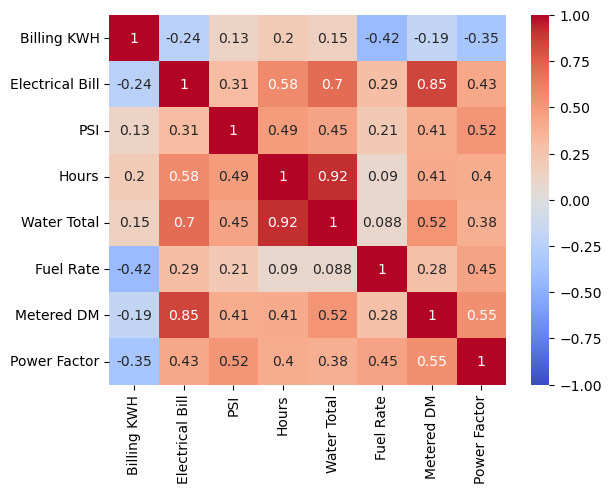

In [41]:
# basic correlation plot
corr_data = main_df[["Billing KWH", "Electrical Bill", "PSI", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]]
corr_matrix = corr_data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [6]:
exogs = ["PSI", "Billing KWH", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]
endogs = ["Electrical Bill", "Billing KWH", "Water Total", "Metered DM", "Hours"]
os.chdir(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Graphs\Linear")
folder = os.getcwd()
folder = Path(folder)

lm_dict = datamine_ls(endogs, exogs, main_df)

In [4]:
write_ls_summaries(lm_dict, input_path=os.getcwd())

In [7]:
# Plot the relationships which can be visualized
# and plot the residuals for all relationships.
for label, lm in lm_dict.items():
    plot_ls(lm, os.getcwd())
    

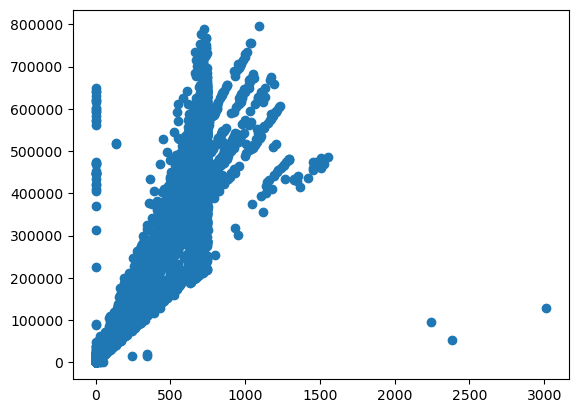

In [9]:
PCA_test = ["Hours", "Water Total"]
fig, ax = plt.subplots()
ax.scatter(main_df["Hours"], main_df["Water Total"])

In [8]:
# Standard Linear Regression
# PREDICTIVE
# Exploration of KWH and billing relationships
# Variables of interest: Predictors: Hours, Water Total, PSI, Metered DM, Power Factor, Billed DM, Fuel Rate
#                        Predicted: Billing KWH
predictors = ["Hours", "Water Total", "PSI", "Metered DM", "Power Factor", "Billed DM", "Fuel Rate"]
predicted = ["Billing KWH",]

# We need to split dataset based on time, rather than randomly. The last observation for the data is September 2025.
# Let's attempt to predict 6 months worth of data, so the training set will be start -> March 2025
X = main_df[predictors]
y = main_df[predicted]

print(main_df["Year-Month"])

train_X = main_df[main_df["Year-Month"] < "2025-04"]
train_X = train_X[predictors]

test_X = main_df[main_df["Year-Month"] >= "2025-04"]
test_X = test_X[predictors]

train_y = main_df[main_df["Year-Month"] < "2025-04"]
train_y = train_y[predicted]

test_y = main_df[main_df["Year-Month"] >= "2025-04"]
test_y = test_y[predicted]


# Normalization - NOTE: We are explaining rather than predicting in this case, so normalization should transform
#                       all data and not just the training data whose values are applied to the test data.
# NOTE: Normalization applies to PCA and other methods sensitive to absolute magnitude differences. 
#       OLS linear regression is not one of those.

0       2017-08
1       2017-09
2       2017-10
3       2017-11
4       2017-12
         ...   
8521    2025-05
8522    2025-06
8523    2025-07
8524    2025-08
8525    2025-09
Name: Year-Month, Length: 8526, dtype: object


In [ ]:
# Principle Components Analysis
# Principle Components Regression 